# Promotion uplift: did displays and mailers raise sales?
84.51° *The Complete Journey* 2.0 (via the `completejourney` package). This notebook re-runs every reported query against `promo.duckdb`; rebuild the database with `python run_all.py`.

**Summary.** A before-and-after comparison puts display-week uplift at about +60%. Comparing stores with and without the display in the same week gives +33% across all display weeks. For isolated display runs, sales were already +21% against control stores the week before, so the run-period uplift is reported as a range, about +30% to +55%. Display weeks also carry deeper loyalty discounts, so this is the effect of display plus price cut. There is no evidence of a dip in the four weeks after a display ends.

In [1]:
import pathlib, duckdb, pandas as pd
from IPython.display import Image
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
con = duckdb.connect(str(ROOT / 'promo.duckdb'), read_only=True)
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
q = lambda sql: con.execute(sql).df()

## Step 1: data checks
`02_checks.sql`. Blocking checks must show 0 failures. The funnel shows what each cleaning rule removed.

**blocking**

In [2]:
q("""
SELECT 'spine key is unique' AS test,
       (SELECT COUNT(*) - COUNT(DISTINCT (product_id, store_id, week)) FROM spine) AS failures
UNION ALL
SELECT 'spine rows = pairs x weeks',
       (SELECT COUNT(*) FROM spine)
       - (SELECT COUNT(*) FROM (SELECT DISTINCT product_id, store_id FROM sales_psw))
         * (SELECT COUNT(*) FROM week_calendar WHERE in_scope)
UNION ALL
SELECT 'spine net sales reconcile to clean transactions (cents)',
       ROUND(100 * ABS((SELECT SUM(net_sales) FROM spine) - (SELECT SUM(sales_value) FROM tx_clean)))
UNION ALL
SELECT 'promo flags unique after collapsing duplicates',
       (SELECT COUNT(*) - COUNT(DISTINCT (product_id, store_id, week)) FROM promo_flags)
UNION ALL
SELECT 'shelf value >= net value on every row',
       (SELECT COUNT(*) FROM tx_clean WHERE shelf_value < sales_value)
""")

,test,failures
0,spine key is unique,0.0
1,spine rows = pairs x weeks,0.0
2,spine net sales reconcile to clean transaction...,0.0
3,promo flags unique after collapsing duplicates,0.0
4,shelf value >= net value on every row,0.0


**row_funnel**: what each rule removed from transactions

In [3]:
q("""
SELECT 'all transaction rows'                    AS step, COUNT(*) AS rows, ROUND(SUM(sales_value)) AS net_sales FROM transactions
UNION ALL SELECT 'in the 112 promotion stores', COUNT(*), ROUND(SUM(sales_value)) FROM transactions JOIN promo_stores USING (store_id)
UNION ALL SELECT '... and weeks 2-53',          COUNT(*), ROUND(SUM(sales_value)) FROM transactions JOIN promo_stores USING (store_id) WHERE week BETWEEN 2 AND 53
UNION ALL SELECT '... dropped: quantity = 0',   COUNT(*), ROUND(SUM(sales_value)) FROM transactions JOIN promo_stores USING (store_id) WHERE week BETWEEN 2 AND 53 AND quantity <= 0
UNION ALL SELECT '... dropped: value = 0 (qty > 0)', COUNT(*), ROUND(SUM(sales_value)) FROM transactions JOIN promo_stores USING (store_id) WHERE week BETWEEN 2 AND 53 AND quantity > 0 AND sales_value <= 0
UNION ALL SELECT 'clean rows (tx_clean)',       COUNT(*), ROUND(SUM(sales_value)) FROM tx_clean
""")

,step,rows,net_sales
0,all transaction rows,1469307,4596040.0
1,in the 112 promotion stores,1450275,4531026.0
2,... and weeks 2-53,1446581,4520642.0
3,... dropped: quantity = 0,8773,13.0
4,... dropped: value = 0 (qty > 0),2390,0.0
5,clean rows (tx_clean),1435418,4520629.0


**promo_duplicates**

In [4]:
q("""
SELECT COUNT(*) FILTER (WHERE source_rows > 1) AS keys_with_duplicate_rows,
       SUM(source_rows) - COUNT(*)            AS rows_collapsed,
       COUNT(*)                               AS product_store_weeks_promoted
FROM promo_flags
""")

,keys_with_duplicate_rows,rows_collapsed,product_store_weeks_promoted
0,12785,12785.0,20927744


**spine_profile**

In [5]:
q("""
SELECT COUNT(*)                                             AS spine_rows,
       COUNT(DISTINCT (product_id, store_id))               AS product_store_pairs,
       COUNT(DISTINCT product_id)                           AS products,
       ROUND(100.0 * AVG((units = 0)::INT), 1)              AS pct_rows_zero_sales,
       ROUND(100.0 * AVG((promo_type <> 'none')::INT), 1)   AS pct_rows_promoted,
       ROUND(100.0 * AVG((promo_type <> 'none' AND units = 0)::INT)
             / NULLIF(AVG((promo_type <> 'none')::INT), 0), 1) AS pct_promoted_rows_with_zero_sales
FROM spine
""")

,spine_rows,product_store_pairs,products,pct_rows_zero_sales,pct_rows_promoted,pct_promoted_rows_with_zero_sales
0,31860764,612707,55909,95.9,9.1,90.7


**promo_mix**

In [6]:
q("""
SELECT promo_type, COUNT(*) AS rows, ROUND(SUM(net_sales)) AS net_sales,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_rows
FROM spine GROUP BY promo_type ORDER BY rows DESC
""")

,promo_type,rows,net_sales,pct_rows
0,none,28947618,3630613.0,90.86
1,mailer only,1669128,491584.0,5.24
2,display only,868214,222849.0,2.73
3,display + mailer,375804,175584.0,1.18


**loyalty_depth_mix**: weeks with a sale only

In [7]:
q("""
SELECT loyalty_depth, COUNT(*) AS rows_with_sale, ROUND(SUM(net_sales)) AS net_sales
FROM spine WHERE units > 0 GROUP BY loyalty_depth ORDER BY rows_with_sale DESC
""")

,loyalty_depth,rows_with_sale,net_sales
0,none,656003,2217547.0
1,over 25%,302530,862699.0
2,10-25%,262982,806938.0
3,under 10%,85200,633446.0


**discount_funding**

In [8]:
q("""
SELECT ROUND(SUM(net_sales))         AS net_sales,
       ROUND(SUM(shelf_sales))       AS shelf_sales,
       ROUND(SUM(loyalty_disc))      AS loyalty_disc_retailer,
       ROUND(SUM(coupon_match_disc)) AS coupon_match_retailer,
       ROUND(SUM(manuf_coupon_disc)) AS manufacturer_coupons
FROM spine
""")

,net_sales,shelf_sales,loyalty_disc_retailer,coupon_match_retailer,manufacturer_coupons
0,4520629.0,5296215.0,771088.0,4497.0,19353.0


**holiday_weeks**

In [9]:
q("""
SELECT w.week, w.first_day, w.last_day, w.holiday, ROUND(SUM(s.net_sales)) AS net_sales
FROM week_calendar w JOIN spine s USING (week)
WHERE w.holiday IS NOT NULL GROUP BY ALL ORDER BY w.week
""")

,week,first_day,last_day,holiday,net_sales
0,48,2017-11-20,2017-11-27,Thanksgiving (23 Nov),91272.0
1,52,2017-12-18,2017-12-24,Christmas week (to 24 Dec),111924.0
2,53,2017-12-26,2018-01-01,Christmas to New Year,80045.0


## Step 2: uplift by promotion type, methods A and B
`03_uplift.sql`. A = the product's own last 4 clean weeks. B = control stores selling the same product that week without a promotion. Ratio of sums, holiday weeks never in a baseline.

**u01_coverage**: how many promoted rows each method can evaluate

In [10]:
q("""
SELECT 'promoted product-store-weeks, full promotions table (112 stores, weeks 2-53)' AS item,
       (SELECT COUNT(*) FROM promo_flags f JOIN week_calendar w USING (week)
        WHERE w.in_scope AND (f.on_display OR f.in_mailer)) AS n
UNION ALL SELECT '... of which in the spine (pair bought at least once)', (SELECT COUNT(*) FROM promo_rows)
UNION ALL SELECT '... evaluable by method A (4 clean prior weeks within 12)', (SELECT COUNT(*) FROM uplift_a)
UNION ALL SELECT '... with usual sales and 3+ control stores (B, before validity rule)', (SELECT COUNT(*) FROM uplift_b_all)
UNION ALL SELECT '... evaluable by method B (<= half of stores promoted, 10+ controls)', (SELECT COUNT(*) FROM uplift_b_rows)
UNION ALL SELECT '... evaluable by both', (SELECT COUNT(*) FROM uplift_a a JOIN uplift_b_rows b USING (product_id, store_id, week))
""")

,item,n
0,"promoted product-store-weeks, full promotions ...",20224239
1,... of which in the spine (pair bought at leas...,2913146
2,... evaluable by method A (4 clean prior weeks...,2334020
3,"... with usual sales and 3+ control stores (B,...",1120876
4,... evaluable by method B (<= half of stores p...,645860
5,... evaluable by both,416345


**u02_uplift_by_type**: ratio of sums; holiday weeks excluded / included

In [11]:
q("""
WITH a AS (
    SELECT promo_type, holiday_week, SUM(net_sales) AS act, SUM(base_net_sales) AS exp,
           SUM(units) AS act_u, SUM(base_units) AS exp_u, COUNT(*) AS n
    FROM uplift_a GROUP BY ALL
), b AS (
    SELECT promo_type, holiday_week, SUM(net_sales) AS act, SUM(expected_net_sales) AS exp,
           SUM(units) AS act_u, SUM(expected_units) AS exp_u, COUNT(*) AS n
    FROM uplift_b_rows GROUP BY ALL
), both_m AS (
    SELECT 'A: time baseline' AS method, * FROM a UNION ALL SELECT 'B: control stores', * FROM b
)
SELECT method, promo_type,
       SUM(n) FILTER (WHERE NOT holiday_week)                                   AS rows_excl_holiday,
       ROUND(100 * (SUM(act) FILTER (WHERE NOT holiday_week)
                  / SUM(exp) FILTER (WHERE NOT holiday_week) - 1), 1)          AS uplift_net_sales_pct_excl_holiday,
       ROUND(100 * (SUM(act_u) FILTER (WHERE NOT holiday_week)
                  / SUM(exp_u) FILTER (WHERE NOT holiday_week) - 1), 1)        AS uplift_units_pct_excl_holiday,
       ROUND(100 * (SUM(act) / SUM(exp) - 1), 1)                               AS uplift_net_sales_pct_all_weeks,
       ROUND(SUM(act) FILTER (WHERE NOT holiday_week)
           - SUM(exp) FILTER (WHERE NOT holiday_week))                          AS extra_net_sales_excl_holiday
FROM both_m
GROUP BY method, promo_type
ORDER BY promo_type, method
""")

,method,promo_type,rows_excl_holiday,uplift_net_sales_pct_excl_holiday,uplift_units_pct_excl_holiday,uplift_net_sales_pct_all_weeks,extra_net_sales_excl_holiday
0,A: time baseline,display + mailer,277587.0,205.5,284.4,206.6,84164.0
1,B: control stores,display + mailer,260.0,67.2,97.9,59.8,34.0
2,A: time baseline,display only,507646.0,61.7,78.0,64.8,45149.0
3,B: control stores,display only,606973.0,33.1,42.8,32.5,33651.0
4,A: time baseline,mailer only,1410508.0,90.3,118.7,91.2,196225.0
5,B: control stores,mailer only,4112.0,41.3,36.9,32.6,155.0


**u03_same_rows**: both methods on the identical set of promoted rows, non-holiday

In [12]:
q("""
SELECT a.promo_type, COUNT(*) AS rows,
       ROUND(100 * (SUM(a.net_sales) / SUM(a.base_net_sales) - 1), 1)      AS uplift_A_pct,
       ROUND(100 * (SUM(b.net_sales) / SUM(b.expected_net_sales) - 1), 1)  AS uplift_B_pct
FROM uplift_a a JOIN uplift_b_rows b USING (product_id, store_id, week)
WHERE NOT a.holiday_week
GROUP BY a.promo_type ORDER BY a.promo_type
""")

,promo_type,rows,uplift_A_pct,uplift_B_pct
0,display + mailer,237,100.0,69.1
1,display only,386612,43.1,41.7
2,mailer only,4016,35.8,39.1


**u04_uplift_by_department**: method A vs B, non-holiday, departments with >= 2,000 rows in both

In [13]:
q("""
WITH a AS (SELECT department, SUM(net_sales) act, SUM(base_net_sales) exp, COUNT(*) n
           FROM uplift_a WHERE NOT holiday_week GROUP BY ALL),
     b AS (SELECT department, SUM(net_sales) act, SUM(expected_net_sales) exp, COUNT(*) n
           FROM uplift_b_rows WHERE NOT holiday_week GROUP BY ALL)
SELECT department, a.n AS rows_A, ROUND(100 * (a.act / a.exp - 1), 1) AS uplift_A_pct,
       b.n AS rows_B, ROUND(100 * (b.act / b.exp - 1), 1) AS uplift_B_pct
FROM a JOIN b USING (department)
WHERE a.n >= 2000 AND b.n >= 2000
ORDER BY uplift_A_pct DESC
""")

,department,rows_A,uplift_A_pct,rows_B,uplift_B_pct
0,PASTRY,33284,127.6,4748,66.0
1,MEAT-PCKGD,165482,125.1,53226,31.7
2,DRUG GM,218662,110.3,89891,54.4
3,SEAFOOD-PCKGD,26545,101.0,10810,44.4
4,NUTRITION,25935,84.2,12511,52.7
5,GROCERY,1493416,83.5,424924,30.2
6,DELI,45537,58.9,3784,21.8
7,PRODUCE,65949,51.4,9564,46.2


**u05_inshelf_sensitivity**: method A, non-holiday: baseline weeks with an in-shelf tag removed

In [14]:
q("""
WITH base2 AS (
    SELECT product_id, store_id, week,
           AVG(net_sales) OVER w4 AS base_net_sales, COUNT(*) OVER w4 AS n4, MIN(week) OVER w4 AS w0
    FROM base_weeks WHERE NOT in_shelf_tag
    WINDOW w4 AS (PARTITION BY product_id, store_id ORDER BY week ROWS BETWEEN 3 PRECEDING AND CURRENT ROW)
), j AS (
    SELECT r.promo_type, r.net_sales, b.base_net_sales
    FROM promo_rows r ASOF JOIN base2 b
      ON r.product_id = b.product_id AND r.store_id = b.store_id AND r.week > b.week
    WHERE b.n4 = 4 AND r.week - b.w0 <= 12 AND NOT r.holiday_week
)
SELECT promo_type, COUNT(*) AS rows, ROUND(100 * (SUM(net_sales) / SUM(base_net_sales) - 1), 1) AS uplift_A_pct_no_inshelf_baseline
FROM j GROUP BY promo_type ORDER BY promo_type
""")

,promo_type,rows,uplift_A_pct_no_inshelf_baseline
0,display + mailer,276086,209.7
1,display only,499380,66.6
2,mailer only,1408886,91.0


**u06_loyalty_depth_description**: descriptive only: depth is observed only when something sold

In [15]:
q("""
SELECT promo_type,
       ROUND(100 * SUM(loyalty_disc) / NULLIF(SUM(shelf_sales), 0), 1) AS avg_loyalty_depth_pct_of_shelf_value,
       COUNT(*) FILTER (WHERE units > 0) AS rows_with_sale
FROM spine GROUP BY promo_type ORDER BY promo_type
""")

,promo_type,avg_loyalty_depth_pct_of_shelf_value,rows_with_sale
0,display + mailer,36.0,56753
1,display only,16.9,71139
2,mailer only,34.1,143784
3,none,9.3,1035039


**u07_why_B_fails_for_mailers**: share of selling stores promoted, and the control index, by type

In [16]:
q("""
SELECT r.promo_type,
       ROUND(MEDIAN(pw.stores_promoted * 1.0 / pw.stores_selling), 3) AS median_share_of_stores_promoted,
       ROUND(MEDIAN(b.ctrl_stores), 0)                                  AS median_control_stores,
       ROUND(SUM(b.ctrl_net_sales) / SUM(b.ctrl_usual_net_sales), 2)    AS control_stores_actual_vs_usual,
       ROUND(100 * (SUM(b.net_sales) / SUM(b.expected_net_sales) - 1), 0) AS naive_uplift_B_pct
FROM promo_rows r
JOIN product_week_share pw USING (product_id, week)
LEFT JOIN (SELECT u.*, c.ctrl_net_sales, c.ctrl_usual_net_sales
           FROM uplift_b_all u JOIN week_control c USING (product_id, week)) b USING (product_id, store_id, week)
WHERE NOT r.holiday_week
GROUP BY r.promo_type ORDER BY r.promo_type
""")

,promo_type,median_share_of_stores_promoted,median_control_stores,control_stores_actual_vs_usual,naive_uplift_B_pct
0,display + mailer,0.981,3.0,0.23,4101.0
1,display only,0.222,34.0,1.13,40.0
2,mailer only,0.981,3.0,0.27,3129.0


## Robustness: method C, placebos, ranges, chronic promotions
`04_robustness.sql`. C measures mailers at product-week level against other categories of the same department. Placebos should be near 0%.

**r01_B_sensitivity**: display only, non-holiday: max share of stores promoted x min control stores

In [17]:
q("""
WITH grid AS (
    SELECT * FROM (VALUES (0.3), (0.5), (0.7)) a(max_share)
    CROSS JOIN (VALUES (5), (10), (20)) b(min_ctrl)
)
SELECT g.max_share, g.min_ctrl, COUNT(*) AS rows,
       ROUND(100 * (SUM(b.net_sales) / SUM(b.expected_net_sales) - 1), 1) AS uplift_B_display_pct
FROM grid g
JOIN uplift_b_all b ON b.promo_type = 'display only' AND NOT b.holiday_week AND b.ctrl_stores >= g.min_ctrl
JOIN product_week_share pw USING (product_id, week)
WHERE pw.stores_promoted <= g.max_share * pw.stores_selling
GROUP BY g.max_share, g.min_ctrl
ORDER BY g.max_share, g.min_ctrl
""")

,max_share,min_ctrl,rows,uplift_B_display_pct
0,0.3,5,483057,36.8
1,0.3,10,449117,34.3
2,0.3,20,377399,33.3
3,0.5,5,657328,35.8
4,0.5,10,606973,33.1
5,0.5,20,503861,31.8
6,0.7,5,727778,36.1
7,0.7,10,670421,33.4
8,0.7,20,553034,32.3


**r02_method_C_mailers**: A at product-week level vs C with other-category control

In [18]:
q("""
SELECT COUNT(*) AS mailer_product_weeks,
       ROUND(100 * (SUM(net_sales) / SUM(base) - 1), 1)                AS uplift_A_productweek_pct,
       ROUND(100 * (SUM(net_sales) / SUM(base * ctrl_index) - 1), 1)   AS uplift_C_pct,
       ROUND(SUM(base * ctrl_index) / SUM(base), 3)                    AS avg_control_index,
       ROUND(MEDIAN(ctrl_products))                                     AS median_control_products
FROM uplift_c_rows
""")

,mailer_product_weeks,uplift_A_productweek_pct,uplift_C_pct,avg_control_index,median_control_products
0,45201,121.5,118.7,1.013,17215.0


**r03_placebo**: fake promotions on non-promoted weeks: uplift should be near 0

In [19]:
q("""
WITH a_all_clean AS (           -- A: every clean, non-holiday product-store week with a valid baseline
    SELECT SUM(s.net_sales) AS act, SUM(b.base_net_sales) AS exp, COUNT(*) AS n
    FROM base_weeks s
    ASOF JOIN base_roll b ON s.product_id = b.product_id AND s.store_id = b.store_id AND s.week > b.week
    WHERE b.n_base_weeks = 4 AND s.week - b.first_base_week <= 12
),
a_pre_promo AS (                -- A: the clean week just BEFORE a real promotion, by the type that follows
    SELECT nxt.promo_type, SUM(s.net_sales) AS act, SUM(b.base_net_sales) AS exp, COUNT(*) AS n
    FROM base_weeks s
    JOIN promo_rows nxt ON nxt.product_id = s.product_id AND nxt.store_id = s.store_id AND nxt.week = s.week + 1
    ASOF JOIN base_roll b ON s.product_id = b.product_id AND s.store_id = b.store_id AND s.week > b.week
    WHERE b.n_base_weeks = 4 AND s.week - b.first_base_week <= 12
    GROUP BY nxt.promo_type
),
c_pre_mailer AS (               -- C: the clean product-week just before a mailer week
    SELECT SUM(r.net_sales) AS act,
           SUM(r.base * (d.act - COALESCE(c.act, 0) - r.net_sales) / NULLIF(d.exp - COALESCE(c.exp, 0) - r.base, 0)) AS exp,
           COUNT(*) AS n
    FROM pw_with_base r
    JOIN pw_status nxt ON nxt.product_id = r.product_id AND nxt.week = r.week + 1 AND nxt.status = 'mailer'
    JOIN pw_ctrl_dept d ON d.department = r.department AND d.week = r.week
    LEFT JOIN pw_ctrl_cat c ON c.department = r.department AND c.product_category = r.product_category AND c.week = r.week
    WHERE r.status = 'clean' AND NOT r.holiday_week AND d.n - COALESCE(c.n, 0) >= 20
),
b_fake AS (                     -- B: in product-weeks with NO promotion anywhere, half the stores are "treated" at random
    SELECT s.product_id, s.store_id, s.week, s.net_sales, u.usual_net_sales,
           HASH(s.product_id, s.store_id, s.week) % 2 = 0 AS fake_treated
    FROM spine s
    JOIN store_usual u USING (product_id, store_id)
    JOIN product_week_share pw USING (product_id, week)
    JOIN week_calendar w USING (week)
    WHERE pw.stores_promoted = 0 AND w.holiday IS NULL
),
b_ctrl AS (
    SELECT product_id, week, SUM(net_sales) AS c_act, SUM(usual_net_sales) AS c_usual, COUNT(*) AS n_ctrl
    FROM b_fake WHERE NOT fake_treated GROUP BY ALL
),
b_res AS (
    SELECT SUM(f.net_sales) AS act, SUM(f.usual_net_sales * c.c_act / c.c_usual) AS exp, COUNT(*) AS n
    FROM b_fake f JOIN b_ctrl c USING (product_id, week)
    WHERE f.fake_treated AND c.n_ctrl >= 10 AND c.c_usual > 0
),
c_fake AS (                     -- C: clean product-weeks treated as if they were in the mailer
    SELECT SUM(r.net_sales) AS act,
           SUM(r.base * (d.act - COALESCE(c.act, 0) - r.net_sales) / NULLIF(d.exp - COALESCE(c.exp, 0) - r.base, 0)) AS exp,
           COUNT(*) AS n
    FROM pw_with_base r
    JOIN pw_ctrl_dept d USING (department, week)
    LEFT JOIN pw_ctrl_cat c USING (department, product_category, week)
    WHERE r.status = 'clean' AND NOT r.holiday_week AND d.n - COALESCE(c.n, 0) >= 20
)
SELECT 'A: all clean weeks as fake promotions' AS placebo, n AS rows, ROUND(100 * (act / exp - 1), 1) AS uplift_pct FROM a_all_clean
UNION ALL SELECT 'A: clean week just before a ' || promo_type || ' week', n, ROUND(100 * (act / exp - 1), 1) FROM a_pre_promo
UNION ALL SELECT 'B: random half of stores in unpromoted product-weeks', n, ROUND(100 * (act / exp - 1), 1) FROM b_res
UNION ALL SELECT 'C: clean product-weeks vs other-category control', n, ROUND(100 * (act / exp - 1), 1) FROM c_fake
UNION ALL SELECT 'C: clean product-week just before a mailer week', n, ROUND(100 * (act / exp - 1), 1) FROM c_pre_mailer
""")

,placebo,rows,uplift_pct
0,A: all clean weeks as fake promotions,24744598,0.6
1,A: clean week just before a display only week,182188,30.6
2,A: clean week just before a display + mailer week,180172,11.6
3,A: clean week just before a mailer only week,1057466,6.5
4,B: random half of stores in unpromoted product...,5756364,0.8
5,C: clean product-weeks vs other-category control,2187898,4.4
6,C: clean product-week just before a mailer week,30740,6.5


**r04_week_ranges**: ratio of sums per week, then median and spread across weeks; weeks with >= 200 rows

In [20]:
q("""
WITH a AS (SELECT 'A' AS m, promo_type, week, SUM(net_sales) / SUM(base_net_sales) - 1 AS u, COUNT(*) AS n
           FROM uplift_a WHERE NOT holiday_week GROUP BY ALL),
     b AS (SELECT 'B', promo_type, week, SUM(net_sales) / SUM(expected_net_sales) - 1, COUNT(*)
           FROM uplift_b_rows WHERE NOT holiday_week GROUP BY ALL),
     c AS (SELECT 'C', 'mailer (product-week)', week, SUM(net_sales) / SUM(base * ctrl_index) - 1, COUNT(*)
           FROM uplift_c_rows GROUP BY ALL),
     wk AS (SELECT * FROM a UNION ALL SELECT * FROM b UNION ALL SELECT * FROM c)
SELECT m AS method, promo_type, COUNT(*) AS weeks,
       ROUND(100 * MEDIAN(u), 1)                AS median_weekly_uplift_pct,
       ROUND(100 * QUANTILE_CONT(u, 0.25), 1)   AS p25,
       ROUND(100 * QUANTILE_CONT(u, 0.75), 1)   AS p75,
       ROUND(100 * MIN(u), 1)                   AS min_pct,
       ROUND(100 * MAX(u), 1)                   AS max_pct
FROM wk WHERE n >= 200 OR m = 'C'
GROUP BY m, promo_type ORDER BY promo_type, m
""")

,method,promo_type,weeks,median_weekly_uplift_pct,p25,p75,min_pct,max_pct
0,A,display + mailer,45,197.5,175.2,236.9,129.7,326.3
1,A,display only,45,55.9,50.5,75.9,22.9,187.0
2,B,display only,49,32.9,27.3,37.4,17.6,55.4
3,C,mailer (product-week),45,123.2,109.3,138.9,55.6,164.1
4,A,mailer only,45,93.6,77.8,107.2,51.5,143.6
5,B,mailer only,3,-7.5,-8.4,21.9,-9.2,51.3


**r05_quarter_ranges**: ratio of sums per quarter

In [21]:
q("""
WITH q AS (SELECT week, CASE WHEN week <= 14 THEN 'Q1' WHEN week <= 27 THEN 'Q2' WHEN week <= 40 THEN 'Q3' ELSE 'Q4' END AS quarter
           FROM week_calendar WHERE in_scope)
SELECT 'A' AS method, a.promo_type, q.quarter, COUNT(*) AS rows,
       ROUND(100 * (SUM(a.net_sales) / SUM(a.base_net_sales) - 1), 1) AS uplift_pct
FROM uplift_a a JOIN q USING (week) WHERE NOT a.holiday_week GROUP BY ALL
UNION ALL
SELECT 'B', b.promo_type, q.quarter, COUNT(*), ROUND(100 * (SUM(b.net_sales) / SUM(b.expected_net_sales) - 1), 1)
FROM uplift_b_rows b JOIN q USING (week) WHERE NOT b.holiday_week AND b.promo_type = 'display only' GROUP BY ALL
UNION ALL
SELECT 'C', 'mailer (product-week)', q.quarter, COUNT(*), ROUND(100 * (SUM(c.net_sales) / SUM(c.base * c.ctrl_index) - 1), 1)
FROM uplift_c_rows c JOIN q USING (week) GROUP BY ALL
ORDER BY 2, 1, 3
""")

,method,promo_type,quarter,rows,uplift_pct
0,A,display + mailer,Q1,52201,209.6
1,A,display + mailer,Q2,88400,207.9
2,A,display + mailer,Q3,82089,207.8
3,A,display + mailer,Q4,54897,194.4
4,A,display only,Q1,72032,64.0
5,A,display only,Q2,165567,55.7
6,A,display only,Q3,151971,51.0
7,A,display only,Q4,118076,84.5
8,B,display only,Q1,155266,31.1
9,B,display only,Q2,164303,31.3


**r06_chronic_promotions**: promoted rows method A cannot evaluate, and why

In [22]:
q("""
SELECT r.promo_type, COUNT(*) AS promoted_rows,
       ROUND(100.0 * AVG((a.n_base_weeks = 4 AND a.week - a.first_base_week <= 12)::INT), 1) AS pct_evaluable_by_A,
       ROUND(100.0 * AVG((a.n_base_weeks IS NULL)::INT), 1)  AS pct_no_clean_week_before,
       ROUND(100.0 * AVG((a.n_base_weeks < 4)::INT), 1)       AS pct_fewer_than_4_clean,
       ROUND(100.0 * AVG((a.n_base_weeks = 4 AND a.week - a.first_base_week > 12)::INT), 1) AS pct_clean_weeks_too_old
FROM promo_rows r
JOIN uplift_a_rows a USING (product_id, store_id, week)
WHERE NOT r.holiday_week
GROUP BY r.promo_type ORDER BY r.promo_type
""")

,promo_type,promoted_rows,pct_evaluable_by_A,pct_no_clean_week_before,pct_fewer_than_4_clean,pct_clean_weeks_too_old
0,display + mailer,357509,82.1,5.4,12.2,5.8
1,display only,823352,68.5,9.9,15.8,15.8
2,mailer only,1575680,91.5,2.2,7.5,1.0


## Step 3: display event study
`05_event_study.sql`. Isolated display runs compared with control stores from 4 weeks before to 4 weeks after.

**e01_episodes**: what the event study covers

In [23]:
q("""
SELECT (SELECT COUNT(*) FROM display_episodes) AS all_display_episodes,
       (SELECT COUNT(*) FROM episodes_ok)      AS usable_episodes,
       (SELECT ROUND(AVG(run_weeks), 2) FROM episodes_ok) AS avg_run_weeks,
       (SELECT ROUND(100.0 * AVG((run_weeks = 1)::INT), 1) FROM episodes_ok) AS pct_one_week_runs
""")

,all_display_episodes,usable_episodes,avg_run_weeks,pct_one_week_runs
0,402452,30918,1.82,63.8


**e02_event_study**: B uplift by week relative to the episode; pre-trend = 'start -1'

In [24]:
q("""
SELECT event_time, MIN(sort_key) AS sort_key, COUNT(*) AS rows,
       ROUND(100 * (SUM(net_sales) / SUM(usual_net_sales * ctrl_index) - 1), 1) AS uplift_vs_controls_pct,
       ROUND(SUM(net_sales) - SUM(usual_net_sales * ctrl_index))               AS extra_net_sales
FROM event_rows
WHERE ctrl_stores >= 10 AND ctrl_index IS NOT NULL
GROUP BY event_time ORDER BY sort_key
""")

,event_time,sort_key,rows,uplift_vs_controls_pct,extra_net_sales
0,start -4,-4,30693,-0.7,-24.0
1,start -3,-3,30698,0.8,27.0
2,start -2,-2,30676,2.5,86.0
3,start -1,-1,30642,21.2,743.0
4,run week 1,0,30916,54.5,2195.0
5,run week 2,1,10961,66.5,873.0
6,run week 3+,2,13795,51.3,867.0
7,end +1,4,30612,9.6,336.0
8,end +2,5,30675,6.8,229.0
9,end +3,6,30693,8.0,258.0


**e03_pre_trend_by_quarter**: week before the start, by quarter of the start week: is it stable?

In [25]:
q("""
SELECT CASE WHEN start_week <= 14 THEN 'Q1' WHEN start_week <= 27 THEN 'Q2' WHEN start_week <= 40 THEN 'Q3' ELSE 'Q4' END AS quarter,
       COUNT(*) AS rows,
       ROUND(100 * (SUM(net_sales) / SUM(usual_net_sales * ctrl_index) - 1), 1) AS start_minus_1_pct
FROM event_rows
WHERE event_time = 'start -1' AND ctrl_stores >= 10 AND ctrl_index IS NOT NULL
GROUP BY 1 ORDER BY 1
""")

,quarter,rows,start_minus_1_pct
0,Q1,6654,22.7
1,Q2,10793,25.1
2,Q3,11326,14.5
3,Q4,1869,35.7


**e04_net_effect**: episode total: extra sales during the run plus the 4 weeks after the end

In [26]:
q("""
SELECT ROUND(SUM(net_sales - usual_net_sales * ctrl_index) FILTER (WHERE phase = 'run'))  AS extra_during_run,
       ROUND(SUM(net_sales - usual_net_sales * ctrl_index) FILTER (WHERE phase = 'post')) AS change_after_end,
       ROUND(SUM(net_sales - usual_net_sales * ctrl_index) FILTER (WHERE phase = 'pre'))  AS change_before_start,
       ROUND(100 * SUM(net_sales - usual_net_sales * ctrl_index) FILTER (WHERE phase = 'post')
             / NULLIF(SUM(net_sales - usual_net_sales * ctrl_index) FILTER (WHERE phase = 'run'), 0), 1) AS post_as_pct_of_run_gain
FROM event_rows
WHERE ctrl_stores >= 10 AND ctrl_index IS NOT NULL
""")

,extra_during_run,change_after_end,change_before_start,post_as_pct_of_run_gain
0,3936.0,837.0,832.0,21.3


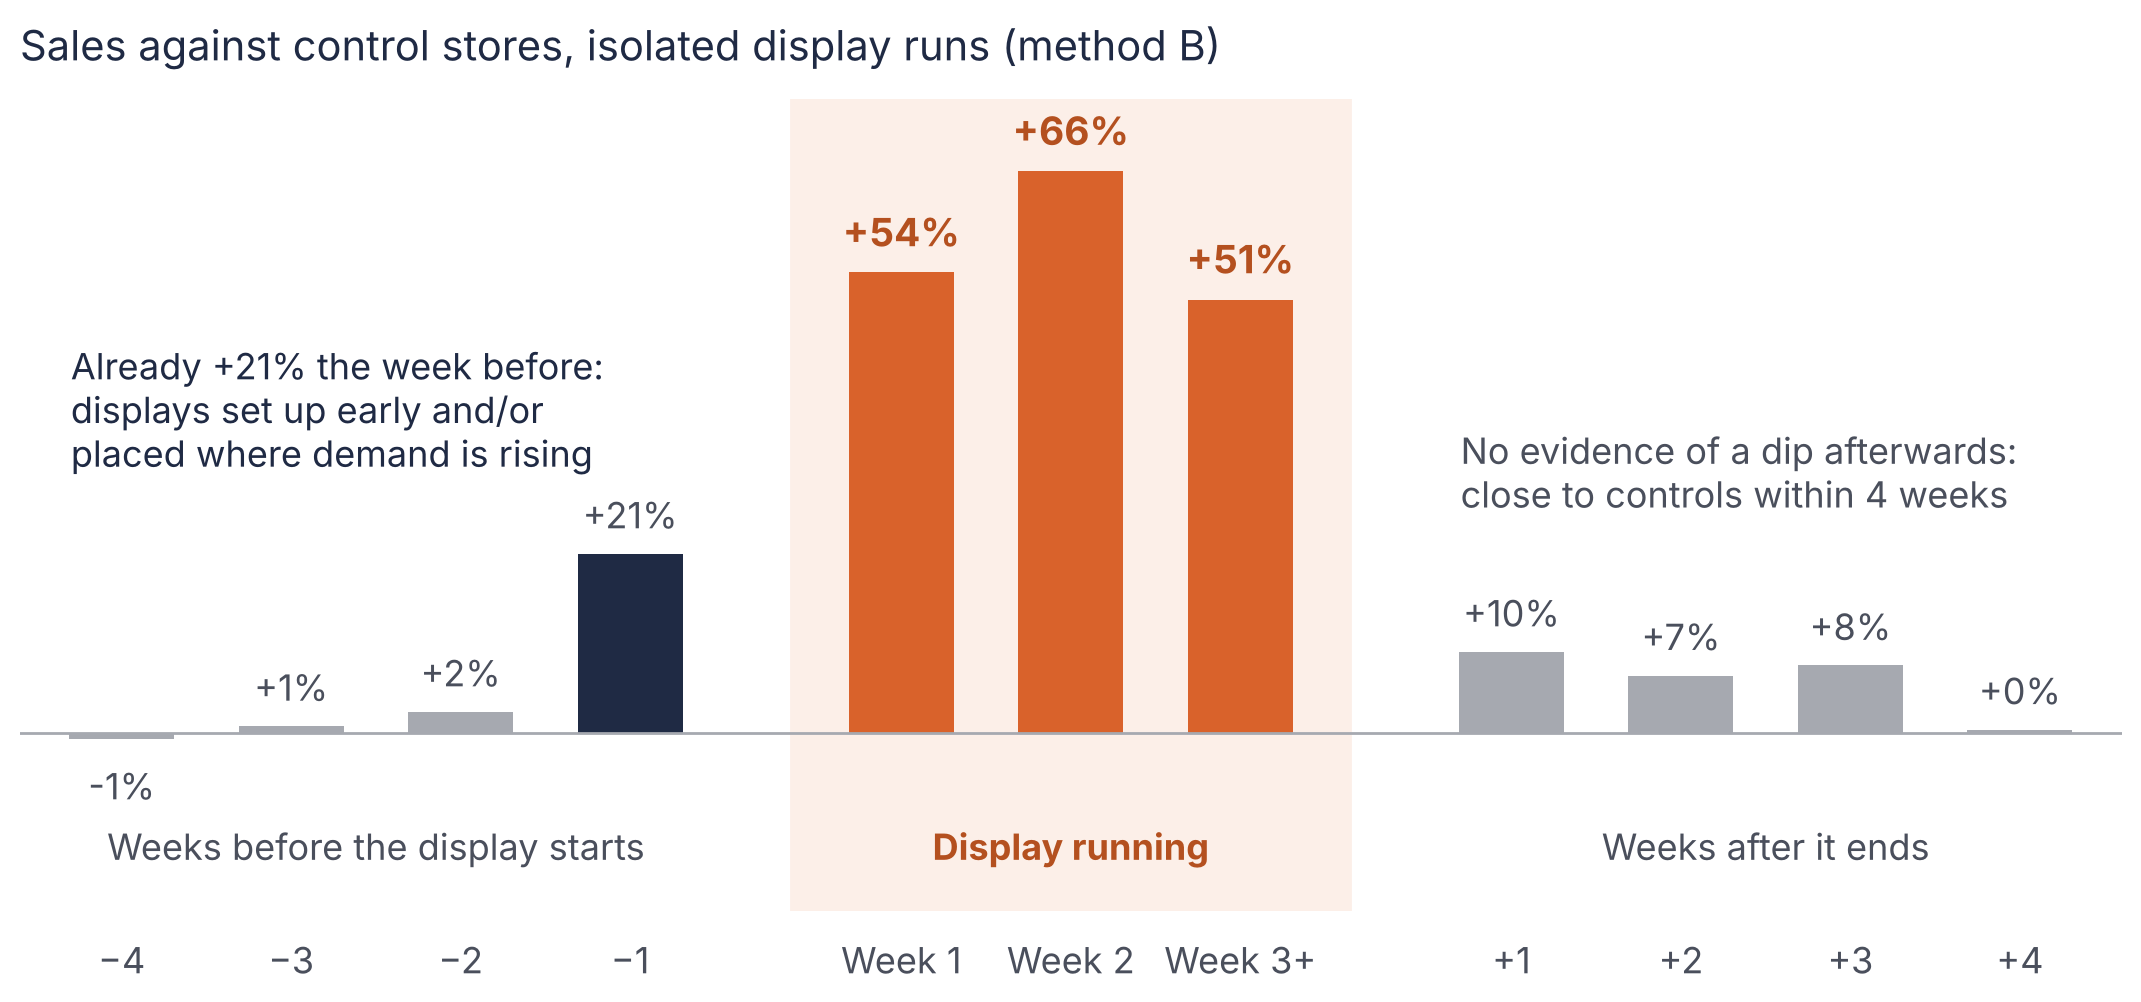

In [27]:
Image(filename=str(ROOT / 'charts/event_study_display.png'), width=900)

## Daily check of the week-before jump
`06_daily_check.sql`. Early set-up predicts a jump at the end of week −1; targeting predicts a jump across the whole week.

**d01_daily_uplift**: ratio of sums by event week and weekday; 1 = Monday

In [28]:
q("""
SELECT CASE k WHEN -2 THEN 'week -2' WHEN -1 THEN 'week -1' ELSE 'run week 1' END AS event_week, k, dow,
       COUNT(*) AS episode_days,
       ROUND(100 * (SUM(treated_sales) / SUM(usual_net_sales * ctrl_sales / ctrl_usual) - 1), 1) AS uplift_vs_controls_pct
FROM event_days
WHERE n_ctrl >= 10 AND ctrl_usual > 0
GROUP BY ALL ORDER BY k, dow
""")

,event_week,k,dow,episode_days,uplift_vs_controls_pct
0,week -2,-2,1,30676,13.5
1,week -2,-2,2,30676,-4.4
2,week -2,-2,3,30676,3.1
3,week -2,-2,4,30676,15.2
4,week -2,-2,5,30676,-5.2
5,week -2,-2,6,30676,-16.0
6,week -2,-2,7,30676,14.5
7,week -1,-1,1,30642,3.7
8,week -1,-1,2,30642,15.5
9,week -1,-1,3,30642,29.6


**d02_week_minus1_halves**: first four days vs last three days of week -1

In [29]:
q("""
SELECT CASE WHEN dow <= 4 THEN 'Mon-Thu' ELSE 'Fri-Sun' END AS part_of_week, k,
       ROUND(100 * (SUM(treated_sales) / SUM(usual_net_sales * ctrl_sales / ctrl_usual) - 1), 1) AS uplift_vs_controls_pct
FROM event_days
WHERE n_ctrl >= 10 AND ctrl_usual > 0
GROUP BY ALL ORDER BY k, part_of_week DESC
""")

,part_of_week,k,uplift_vs_controls_pct
0,Mon-Thu,-2,6.9
1,Fri-Sun,-2,-2.0
2,Mon-Thu,-1,13.5
3,Fri-Sun,-1,29.1
4,Mon-Thu,0,59.6
5,Fri-Sun,0,49.2


**Bootstrap 90% intervals (cluster = product-store)** (`python/bootstrap.py`)

In [30]:
pd.read_csv(ROOT / 'outputs/boot_daily.csv')

,event_week,part,uplift_pct,lo,hi
0,-2,Mon-Thu,6.9,-0.9,15.4
1,-2,Fri-Sun,-2.0,-10.4,7.3
2,-2,late minus early (points),-9.0,-20.5,2.9
3,-1,Mon-Thu,13.5,4.0,23.0
4,-1,Fri-Sun,29.1,19.8,39.4
5,-1,late minus early (points),15.6,0.8,30.0
6,0,Mon-Thu,59.6,49.4,69.3
7,0,Fri-Sun,49.2,39.3,59.6
8,0,late minus early (points),-10.4,-23.3,3.0


## Step 4: cannibalisation
`07_cannibalisation.sql`. The other products of the category in the treated store, against the same products in control stores.

**c01_others_event_study**: other products of the category vs control stores, by event week

In [31]:
q("""
SELECT CASE WHEN phase = 'pre' THEN 'start ' || k WHEN phase = 'run' THEN CASE WHEN k >= 3 THEN 'run week 3+' ELSE 'run week ' || k END ELSE 'end +' || k END AS event_time,
       MIN(CASE WHEN phase = 'pre' THEN k WHEN phase = 'run' THEN LEAST(k, 3) - 1 ELSE 3 + k END) AS sort_key,
       COUNT(*) AS rows,
       ROUND(100 * (SUM(others_net) / SUM(others_usual * ctrl_index) - 1), 2) AS others_vs_controls_pct,
       ROUND(SUM(others_net - others_usual * ctrl_index)) AS others_change_net_sales
FROM cannib_rows
WHERE n_ctrl >= 10 AND ctrl_index IS NOT NULL AND others_usual > 0
GROUP BY event_time ORDER BY sort_key
""")

,event_time,sort_key,rows,others_vs_controls_pct,others_change_net_sales
0,start -4,-4,30606,0.04,94.0
1,start -3,-3,30610,0.10,260.0
2,start -2,-2,30586,1.00,2479.0
3,start -1,-1,30552,1.36,3384.0
4,run week 1,0,30827,1.16,2933.0
5,run week 2,1,10921,0.74,598.0
6,run week 3+,2,13749,-0.63,-592.0
7,end +1,4,30522,-0.55,-1380.0
8,end +2,5,30587,0.21,522.0
9,end +3,6,30604,2.07,5137.0


**c02_net_category_effect**: run weeks: promoted product gain vs change in the rest of the category

In [32]:
q("""
WITH prod AS (
    SELECT SUM(net_sales - usual_net_sales * ctrl_index) AS gain, SUM(usual_net_sales * ctrl_index) AS base
    FROM event_rows WHERE phase = 'run' AND ctrl_stores >= 10 AND ctrl_index IS NOT NULL
), oth AS (
    SELECT SUM(others_net - others_usual * ctrl_index) AS change, SUM(others_usual * ctrl_index) AS base
    FROM cannib_rows WHERE phase = 'run' AND n_ctrl >= 10 AND ctrl_index IS NOT NULL AND others_usual > 0
)
SELECT ROUND(prod.gain)                              AS promoted_product_gain,
       ROUND(oth.change)                             AS rest_of_category_change,
       ROUND(prod.gain + oth.change)                 AS net_category_change,
       ROUND(100 * -oth.change / prod.gain, 1)       AS pct_of_gain_taken_from_rest_of_category,
       ROUND(100 * oth.change / oth.base, 2)         AS rest_of_category_change_pct
FROM prod, oth
""")

,promoted_product_gain,rest_of_category_change,net_category_change,pct_of_gain_taken_from_rest_of_category,rest_of_category_change_pct
0,3936.0,2939.0,6875.0,-74.7,0.69


**Bootstrap 90% intervals, run weeks ($ net sales)** (`python/bootstrap.py`)

In [33]:
pd.read_csv(ROOT / 'outputs/boot_cannibalisation.csv')

,measure,value,lo,hi
0,promoted product gain,3936.0,3539.0,4348.0
1,rest of category change,2939.0,143.0,5758.0
2,net category change,6875.0,3969.0,9933.0


## Steps 5 and 6: break-even scenarios and ranking
`08_breakeven_ranking.sql`. Margins of 20/30/40% are scenarios, not data. Break-even = the most a display-week can cost, as % of normal weekly net sales.

**b01_breakeven**: the extra margin covers a display if one display-week costs less than X% of the product's normal weekly net sales; scenarios, not profit

In [34]:
q("""
WITH t AS (
    SELECT SUM(net_sales) AS net, SUM(shelf_sales) AS shelf, SUM(exp_net) AS exp_net, SUM(exp_shelf) AS exp_shelf
    FROM run_rows
), m AS (SELECT * FROM (VALUES (0.20), (0.30), (0.40)) v(margin)),
b AS (SELECT 'upper (B as measured)' AS bound, 1.0 AS scale UNION ALL SELECT 'lower (week-before jump = targeting)', (SELECT f FROM pre_jump))
SELECT b.bound, m.margin AS gross_margin_scenario,
       ROUND(100 * (t.net / (t.exp_net * b.scale) - 1), 1) AS net_sales_uplift_pct,
       ROUND(100 * (t.shelf / (t.exp_shelf * b.scale) - 1), 1) AS shelf_value_uplift_pct,
       ROUND(100 * ((t.net - t.exp_net * b.scale) - (1 - m.margin) * (t.shelf - t.exp_shelf * b.scale))
                 / (t.exp_net * b.scale), 1) AS breakeven_cost_pct_of_normal_weekly_sales
FROM t, m, b
ORDER BY b.bound DESC, m.margin
""")

,bound,gross_margin_scenario,net_sales_uplift_pct,shelf_value_uplift_pct,breakeven_cost_pct_of_normal_weekly_sales
0,upper (B as measured),0.2,56.0,71.5,-9.3
1,upper (B as measured),0.3,56.0,71.5,-1.1
2,upper (B as measured),0.4,56.0,71.5,7.0
3,lower (week-before jump = targeting),0.2,28.7,41.5,-9.2
4,lower (week-before jump = targeting),0.3,28.7,41.5,-4.5
5,lower (week-before jump = targeting),0.4,28.7,41.5,0.3


**b02_department_counts**: how many usable episodes each department / category has

In [35]:
q("""
SELECT department, COUNT(DISTINCT (product_id, store_id, start_week)) AS episodes, COUNT(*) AS run_weeks
FROM run_rows GROUP BY department ORDER BY episodes DESC
""")

,department,episodes,run_weeks
0,GROCERY,22952,40929
1,DRUG GM,4607,8980
2,MEAT-PCKGD,1197,1764
3,PRODUCE,658,1367
4,NUTRITION,494,1070
5,PASTRY,455,612
6,DELI,193,404
7,SEAFOOD-PCKGD,184,295
8,MEAT,65,87
9,FLORAL,47,59


**b03_department_table**: step 6: uplift, discount depth and break-even by department, >= 300 episodes,

In [36]:
q("""
--                          bootstrap 90% ranges over episodes are added in python, see notebook)
SELECT department,
       COUNT(DISTINCT (product_id, store_id, start_week))                                   AS episodes,
       ROUND(100 * (SUM(net_sales) / SUM(exp_net) - 1), 1)                                  AS uplift_upper_pct,
       ROUND(100 * (SUM(net_sales) / (SUM(exp_net) * (SELECT f FROM pre_jump)) - 1), 1)     AS uplift_lower_pct,
       ROUND(100 * (1 - SUM(exp_net) / SUM(exp_shelf)), 1)                                  AS usual_discount_pct,
       ROUND(100 * (1 - SUM(net_sales) / SUM(shelf_sales)), 1)                              AS display_discount_pct,
       ROUND(100 * ((SUM(net_sales) - SUM(exp_net)) - 0.7 * (SUM(shelf_sales) - SUM(exp_shelf))) / SUM(exp_net), 1) AS breakeven_30_upper,
       ROUND(100 * ((SUM(net_sales) - SUM(exp_net)) - 0.6 * (SUM(shelf_sales) - SUM(exp_shelf))) / SUM(exp_net), 1) AS breakeven_40_upper
FROM run_rows
GROUP BY department HAVING COUNT(DISTINCT (product_id, store_id, start_week)) >= 300
ORDER BY uplift_upper_pct DESC
""")

,department,episodes,uplift_upper_pct,uplift_lower_pct,usual_discount_pct,display_discount_pct,breakeven_30_upper,breakeven_40_upper
0,PASTRY,455,125.4,85.9,7.3,10.5,24.6,39.0
1,MEAT-PCKGD,1197,107.2,70.9,14.2,25.5,-5.8,10.3
2,DRUG GM,4607,89.7,56.5,10.1,16.8,8.0,19.7
3,NUTRITION,494,49.4,23.2,12.5,20.4,-2.0,5.3
4,PRODUCE,658,49.4,23.3,5.9,12.6,4.2,10.6
5,GROCERY,22952,47.2,21.4,12.6,20.7,-2.6,4.5


**Step 6 ranking with bootstrap 90% ranges (≥ 300 episodes)** (`python/bootstrap.py`)

In [37]:
pd.read_csv(ROOT / 'docs/ranking_display_uplift.csv')

,level,name,episodes,range90_lo,uplift_upper_pct,range90_hi,uplift_lower_pct,extra_net_sales_total,breakeven_40_pct
0,department,MEAT-PCKGD,1197,73.5,107.2,151.2,70.9,336.5,10.3
1,department,DRUG GM,4607,66.4,89.7,114.6,56.5,717.5,19.7
2,department,PASTRY,455,57.3,125.4,204.2,85.9,92.3,39.0
3,department,GROCERY,22952,41.0,47.2,54.0,21.4,2524.5,4.5
4,department,PRODUCE,658,24.1,49.4,79.5,23.3,118.0,10.6
5,department,NUTRITION,494,8.7,49.4,99.9,23.2,57.3,5.3
6,product_category,CANDY - PACKAGED,1469,120.6,165.4,214.8,119.0,346.3,38.6
7,product_category,COOKIES/CONES,864,75.6,111.3,150.1,74.3,152.1,21.8
8,product_category,FROZEN PIZZA,742,73.6,119.8,173.5,81.3,187.5,9.0
9,product_category,FRZN MEAT/MEAT DINNERS,644,61.4,116.8,173.6,78.9,105.2,5.5


## Limits
See `docs/DEFINITIONS.md`, section *Limits (final)*. In short: the display result applies to isolated, mostly one-week displays (7.7% of display runs qualify, 30,918 of 402,452, and 64% of those last one week); displays are not random, so the effect is a range; mailers are a package of ad plus price cut; no cost data, so break-even uses margin scenarios.